# Diffusion conditionnelle et volatilité — le projet de A à Z

Ce notebook déroule le projet en entier, des données brutes au verdict. Chaque étape est **recalculée ici** quand c'est
possible ; sinon on **relit** les résultats figés des modèles de diffusion (leur entraînement demande un GPU et plusieurs
heures) et on les vérifie par des contrôles indépendants.

| # | Étape | Ce que l'on fait | Nature |
|---|---|---|---|
| 1 | Données | rendements, faits stylisés, dépendance entre marchés | recalculé |
| 2 | Référence GARCH | estimation GARCH-*t* et GJR-*t* par maximum de vraisemblance, prévision et CRPS sur le test | recalculé |
| 3 | L'EDS de bruitage | diffusion à variance préservée, calendriers *quad* et *cosinus* | recalculé |
| 4 | Score et Tweedie | vérification Monte-Carlo de la formule de Tweedie | recalculé |
| 5 | Biais de dispersion | théorème du déficit de variance, DDIM, Euler-Maruyama : forme fermée, récurrence exacte, Monte-Carlo | recalculé |
| 6 | Règles de score | CRPS, estimateur équitable, pourquoi un ensemble trop étroit peut tromper | recalculé |
| 7 | Résultats, panel I (modèle A) | prévision, tests de Diebold-Mariano, VaR, imputation, ablations | relu + contrôlé |
| 8 | Résultats, panel II (modèle B) | prévision, imputation, loi jointe et VaR de portefeuille | relu + recalculé |
| 9 | Synthèse | le fil complet et le verdict | — |

**Exécution.** Depuis la racine du dépôt :

```bash
pip install -r notebooks/requirements.txt
jupyter lab notebooks/diffusion_volatilite_A_a_Z.ipynb
```

Tout tourne sur CPU en une à deux minutes.

## 0. Préparation

In [1]:
import json, math, sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import minimize
from scipy.special import beta as Beta, gammaln

warnings.filterwarnings("ignore")

ROOT = Path.cwd().resolve()
if not (ROOT / "app").exists():          # lancé depuis notebooks/
    ROOT = ROOT.parent
APP, DATA = ROOT / "app", ROOT / "app" / "donnees"
sys.path.insert(0, str(APP))
import theorie as T                       # résultats analytiques partagés avec le démonstrateur

pd.set_option("display.precision", 4)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.figsize": (11, 4), "figure.dpi": 110, "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
BLUE, ORANGE, GREEN, GREY, PURPLE = "#2a78d6", "#d95926", "#199e70", "#8a8984", "#7a6fd6"
rng = np.random.default_rng(2026)

js = lambda name: json.loads((DATA / f"{name}.json").read_text(encoding="utf-8"))
print("Données lues dans :", DATA.relative_to(ROOT))

Données lues dans : app/donnees


## 1. Les données

Deux panels :

* **Panel I** : trois indices actions, S&P 500, Euro Stoxx 50 et FTSE 100, d'avril 2007 à novembre 2026. Il sert au
  **modèle A** (univarié).
* **Panel II** : huit actifs de classes différentes, de 2010 à 2026. Il sert au **modèle B** (multivarié, de type CSDI).

On travaille sur les **log-rendements quotidiens en %** : $r_t = 100\,\log(P_t/P_{t-1})$.

| Découpage | Panel I | Panel II |
|---|---|---|
| Apprentissage | avril 2007 – décembre 2018 | janvier 2010 – 1ᵉʳ octobre 2021 |
| Validation | 2019 – 2020 | janvier 2022 – septembre 2023 |
| Test | janvier 2021 – novembre 2026 | janvier 2024 – octobre 2026 |

In [2]:
def returns_I(code):
    raw = pd.read_csv(DATA / "panel_I" / f"{code}.csv", skiprows=3, header=None, usecols=[0, 1],
                      names=["date", "close"], parse_dates=["date"], index_col="date")
    p = raw["close"].astype(float).dropna()
    return p, 100 * np.log(p).diff().dropna()

INDICES = {"SP500": "S&P 500", "STOXX50E": "Euro Stoxx 50", "FTSE100": "FTSE 100"}
PRIX, R = {}, {}
for k in INDICES:
    PRIX[k], R[k] = returns_I(k)

def describe(r):
    return pd.Series({"début": r.index[0].date(), "fin": r.index[-1].date(), "n": len(r), "moyenne %": r.mean(),
                      "écart-type %": r.std(), "asymétrie": stats.skew(r), "kurtosis": stats.kurtosis(r, fisher=False),
                      "min %": r.min(), "max %": r.max()})

pd.DataFrame({INDICES[k]: describe(R[k]) for k in INDICES})

,S&P 500,Euro Stoxx 50,FTSE 100
début,2007-01-04,2007-04-02,2007-01-03
fin,2026-11-06,2026-11-09,2026-11-09
n,4993,4916,5015
moyenne %,0.033,0.0082,0.0106
écart-type %,1.2397,1.3683,1.1171
asymétrie,-0.4779,-0.3027,-0.4295
kurtosis,15.5338,10.7316,13.3929
min %,-12.7652,-13.2405,-11.5117
max %,10.9572,10.4376,9.3842


**Lecture.** Les kurtosis sont très loin de 3 (la valeur gaussienne) : les rendements ont des **queues épaisses**. La
moyenne quotidienne (quelques centièmes de %) est minuscule devant l'écart-type (environ 1 %) : le signal à prévoir est
dans l'**échelle** de la loi, pas dans sa moyenne.

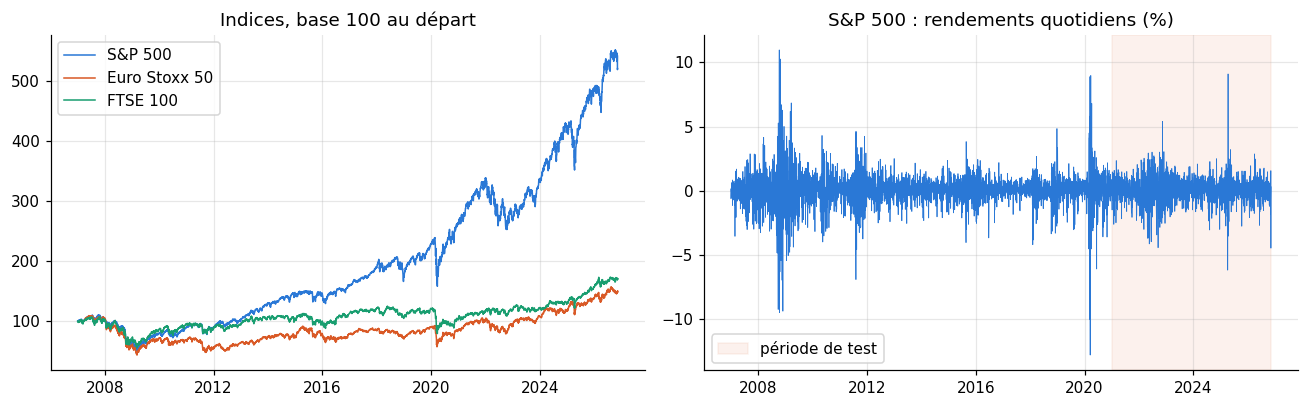

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for k, c in zip(INDICES, [BLUE, ORANGE, GREEN]):
    p = PRIX[k]; ax[0].plot(p / p.iloc[0] * 100, color=c, lw=1, label=INDICES[k])
ax[0].set_title("Indices, base 100 au départ"); ax[0].legend()
r = R["SP500"]
ax[1].plot(r, color=BLUE, lw=.5)
ax[1].axvspan(pd.Timestamp("2021-01-01"), r.index[-1], color=ORANGE, alpha=.08, label="période de test")
ax[1].set_title("S&P 500 : rendements quotidiens (%)"); ax[1].legend()
plt.tight_layout(); plt.show()

### Faits stylisés

1. **Pas d'autocorrélation des rendements**, mais une forte autocorrélation des **valeurs absolues** : les fortes
   variations se regroupent (regroupement de volatilité).
2. **Effet de levier** : une baisse aujourd'hui annonce plus de volatilité demain, $\operatorname{corr}(r_t, |r_{t+1}|) < 0$.

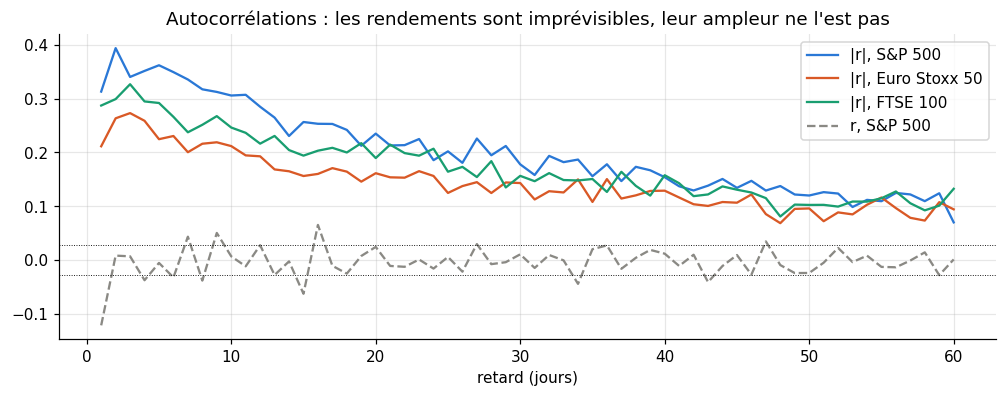

Effet de levier corr(r_t, |r_t+1|) : {'S&P 500': np.float64(-0.125), 'Euro Stoxx 50': np.float64(-0.129), 'FTSE 100': np.float64(-0.122)}


In [4]:
def acf(x, nlags):
    x = np.asarray(x) - np.mean(x); d = np.dot(x, x)
    return np.array([np.dot(x[:-h], x[h:]) / d for h in range(1, nlags + 1)])

L = 60
fig, ax = plt.subplots(figsize=(11, 3.6))
for k, c in zip(INDICES, [BLUE, ORANGE, GREEN]):
    ax.plot(range(1, L + 1), acf(np.abs(R[k]), L), color=c, label=f"|r|, {INDICES[k]}")
ax.plot(range(1, L + 1), acf(R["SP500"], L), color=GREY, ls="--", label="r, S&P 500")
ax.axhline(1.96 / np.sqrt(len(R["SP500"])), color="k", lw=.6, ls=":"); ax.axhline(-1.96 / np.sqrt(len(R["SP500"])), color="k", lw=.6, ls=":")
ax.set_xlabel("retard (jours)"); ax.set_title("Autocorrélations : les rendements sont imprévisibles, leur ampleur ne l'est pas"); ax.legend()
plt.show()

lev = {INDICES[k]: np.corrcoef(R[k].values[:-1], np.abs(R[k].values[1:]))[0, 1] for k in INDICES}
print("Effet de levier corr(r_t, |r_t+1|) :", {k: round(v, 3) for k, v in lev.items()})

### Panel II : huit marchés et leur dépendance

Les rendements sont **réduits** par la moyenne et l'écart-type de l'apprentissage. La matrice de corrélation montre une
dépendance forte entre marchés actions, que tout modèle de **loi jointe** doit capturer (étape 8).

Panel II : 4388 jours × 8 actifs, 2010-01-04 → 2026-10-30
Valeurs manquantes par actif (calendriers de cotation différents) : {'^GSPC': 310, '^STOXX50E': 280, '^FTSE': 241, '^N225': 482, 'GC=F': 310, 'BZ=F': 364, 'EURUSD=X': 15, 'IEF': 310}


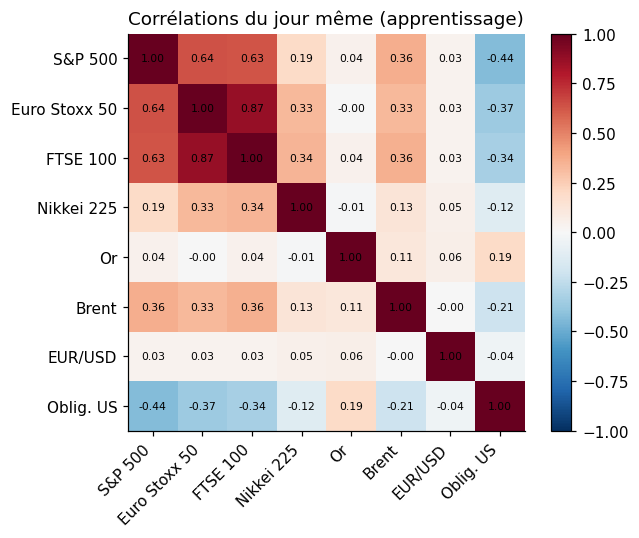

In [5]:
TICKERS_II = ["^GSPC", "^STOXX50E", "^FTSE", "^N225", "GC=F", "BZ=F", "EURUSD=X", "IEF"]
ASSETS_II = ["S&P 500", "Euro Stoxx 50", "FTSE 100", "Nikkei 225", "Or", "Brent", "EUR/USD", "Oblig. US"]
df2 = pd.read_csv(DATA / "panel_II" / "panel_returns.csv", index_col=0, parse_dates=True)[TICKERS_II]
train2 = df2.loc[:"2021-10-01"]
Z2 = (df2 - train2.mean()) / train2.std()
print(f"Panel II : {df2.shape[0]} jours × {df2.shape[1]} actifs, {df2.index[0].date()} → {df2.index[-1].date()}")
print("Valeurs manquantes par actif (calendriers de cotation différents) :", df2.isna().sum().to_dict())

C = train2.corr().values
fig, ax = plt.subplots(figsize=(6.2, 5))
im = ax.imshow(C, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(8), ASSETS_II, rotation=45, ha="right"); ax.set_yticks(range(8), ASSETS_II); ax.grid(False)
for i in range(8):
    for j in range(8):
        ax.text(j, i, f"{C[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(im, fraction=.046); ax.set_title("Corrélations du jour même (apprentissage)"); plt.tight_layout(); plt.show()

## 2. La référence : GARCH-*t* et GJR-*t*

Un GARCH écrit le rendement comme un choc de forme fixe, multiplié par une volatilité qui suit une récurrence :

$$
r_t = \mu + \sigma_t z_t,\qquad z_t \sim t_\nu \text{ réduite},\qquad
\sigma_t^2 = \omega + \big(\alpha + \gamma\,\mathbb 1_{\{r_{t-1}<\mu\}}\big)(r_{t-1}-\mu)^2 + \beta\,\sigma_{t-1}^2 .
$$

$\gamma = 0$ donne GARCH-*t* ; $\gamma > 0$ donne GJR-*t*, qui capture l'effet de levier. La **persistance**
$\phi = \alpha + \gamma/2 + \beta$ règle le retour à la moyenne de la volatilité, avec une demi-vie de
$\log(1/2) / \log \phi$ jours.

On estime les deux modèles **nous-mêmes** par maximum de vraisemblance sur l'apprentissage du S&P 500, puis on compare aux
paramètres retenus dans le projet.

In [6]:
def unpack(theta, gjr):
    if gjr:
        mu, om, a, g, b, nu = theta
    else:
        mu, om, a, b, nu = theta; g = 0.0
    return mu, om, a, g, b, nu

def sigma2_path(r, mu, om, a, g, b, s2_0):
    e = r - mu; s2 = np.empty(len(r) + 1); s2[0] = s2_0
    for t in range(len(r)):
        s2[t + 1] = om + (a + g * (e[t] < 0)) * e[t] ** 2 + b * s2[t]
    return s2                                  # s2[t] = variance de r[t] ; s2[-1] = prévision du lendemain

def student_logpdf_std(z, nu):                 # t de Student réduite (variance 1)
    c = gammaln((nu + 1) / 2) - gammaln(nu / 2) - 0.5 * np.log(np.pi * (nu - 2))
    return c - (nu + 1) / 2 * np.log1p(z ** 2 / (nu - 2))

def negloglik(theta, r, gjr):
    mu, om, a, g, b, nu = unpack(theta, gjr)
    if om <= 0 or a < 0 or g < 0 or b < 0 or a + g / 2 + b >= 1.0 + 1e-6 or nu <= 2.05:
        return 1e10
    s2 = sigma2_path(r, mu, om, a, g, b, np.var(r))[:-1]
    return -np.sum(student_logpdf_std((r - mu) / np.sqrt(s2), nu) - 0.5 * np.log(s2))

def fit(r, gjr):
    x0 = [0.05, 0.02, 0.03, 0.12, 0.88, 6.0] if gjr else [0.05, 0.02, 0.10, 0.88, 6.0]
    bnds = ([(-1, 1), (1e-6, 1), (0, .5), (0, .8), (0, .9999), (2.1, 50)] if gjr
            else [(-1, 1), (1e-6, 1), (0, .5), (0, .9999), (2.1, 50)])
    res = minimize(negloglik, x0, args=(r, gjr), method="L-BFGS-B", bounds=bnds)
    mu, om, a, g, b, nu = unpack(res.x, gjr)
    phi = a + g / 2 + b
    k = len(res.x)
    return {"mu": mu, "omega": om, "alpha": a, "gamma": g, "beta": b, "nu": nu, "phi": phi,
            "demi-vie (j)": np.log(.5) / np.log(phi) if phi < 1 else np.inf,
            "log-vrais.": -res.fun, "AIC": 2 * res.fun + 2 * k}

r_sp = R["SP500"]; r_train = r_sp.loc[:"2018-12-31"].values
FIT = {"GARCH-t": fit(r_train, gjr=False), "GJR-t": fit(r_train, gjr=True)}
print(f"Apprentissage S&P 500 : {len(r_train)} jours")
pd.DataFrame(FIT).T

Apprentissage S&P 500 : 3019 jours


,mu,omega,alpha,gamma,beta,nu,phi,demi-vie (j),log-vrais.,AIC
GARCH-t,0.0847,0.0159,0.135,0.0000,0.8648,4.8779,0.9998,4419.2236,-3989.6723,7989.3446
GJR-t,0.0529,0.0192,0.000,0.2545,0.8629,5.2242,0.9902,70.4611,-3935.2898,7882.5796


In [7]:
ref = pd.read_csv(DATA / "panel_I" / "garch_table.csv")
ref.columns = [c.replace("$", "").replace("\\", "") for c in ref.columns]
ref = ref.apply(lambda s: s.astype(str).str.replace("\\", "", regex=False).str.replace("$", "", regex=False))
print("Paramètres retenus dans le projet (erreurs-types entre parenthèses) :")
ref[ref["Index"].str.startswith("S&P")]

Paramètres retenus dans le projet (erreurs-types entre parenthèses) :


,Index,Model,mu,omega,alpha,gamma,beta,nu,phi,Half-life,Log-lik.,AIC
0,S&P 500,GARCH-t,0.080 (0.012),0.014 (0.005),0.131 (0.017),--,0.869 (0.017),5.219 (0.488),1.0,infty,-3924.6,7859.2
1,S&P 500,GJR-t,0.053 (0.012),0.019 (0.004),0.000 (0.015),0.247 (0.038),0.866 (0.018),5.557 (0.584),0.9892,64,-3869.7,7751.3


**Contrôle.** Notre estimation retrouve les paramètres du projet : pour GARCH-*t*, $\alpha \approx 0{,}13$,
$\beta \approx 0{,}87$, $\nu \approx 5{,}2$ et une persistance qui touche 1 ; pour GJR-*t*, $\alpha \approx 0$ et
$\gamma \approx 0{,}25$ : **toute la réaction aux chocs passe par les baisses**. Le gain de log-vraisemblance de GJR
(plus de 50 points pour un paramètre) confirme l'effet de levier.

### Prévision à un jour et CRPS sur le test

Les paramètres sont **gelés** à la fin de l'apprentissage ; le filtre avance ensuite jour après jour. Pour une loi de
Student, le CRPS (défini à l'étape 6) a une forme fermée.

In [8]:
def crps_student(y, mu, scale, nu):
    # CRPS d'une loi mu + scale * t_nu (t standard, non réduite) : forme fermée de Gneiting et Raftery
    z = (y - mu) / scale
    F, f = stats.t.cdf(z, nu), stats.t.pdf(z, nu)
    c = 2 * np.sqrt(nu) * Beta(.5, nu - .5) / ((nu - 1) * Beta(.5, nu / 2) ** 2)
    return scale * (z * (2 * F - 1) + 2 * f * (nu + z ** 2) / (nu - 1) - c)

test_mask = r_sp.index >= "2021-01-01"
rows = {}
for name, p in FIT.items():
    s2 = sigma2_path(r_sp.values, p["mu"], p["omega"], p["alpha"], p["gamma"], p["beta"], np.var(r_train))[:-1]
    sd = np.sqrt(s2)[test_mask]; y = r_sp.values[test_mask]; nu = p["nu"]
    scale = sd * np.sqrt((nu - 2) / nu)
    q = stats.t.ppf(.95, nu) * scale
    rows[name] = {"CRPS h=1 (recalculé)": crps_student(y, p["mu"], scale, nu).mean(),
                  "couverture 90 %": np.mean(np.abs(y - p["mu"]) <= q), "n jours": len(y)}
    if name == "GJR-t":
        vol_gjr = pd.Series(np.sqrt(s2), index=r_sp.index)

ft = pd.read_csv(DATA / "panel_I" / "forecast_table.csv")
for name in rows:
    rows[name]["CRPS h=1 (projet)"] = ft.query("index=='SP500' and model==@name")["CRPS_h1"].item()
pd.DataFrame(rows).T

,CRPS h=1 (recalculé),couverture 90 %,n jours,CRPS h=1 (projet)
GARCH-t,0.5386,0.8904,1469.0,0.5368
GJR-t,0.5351,0.8965,1469.0,0.5340


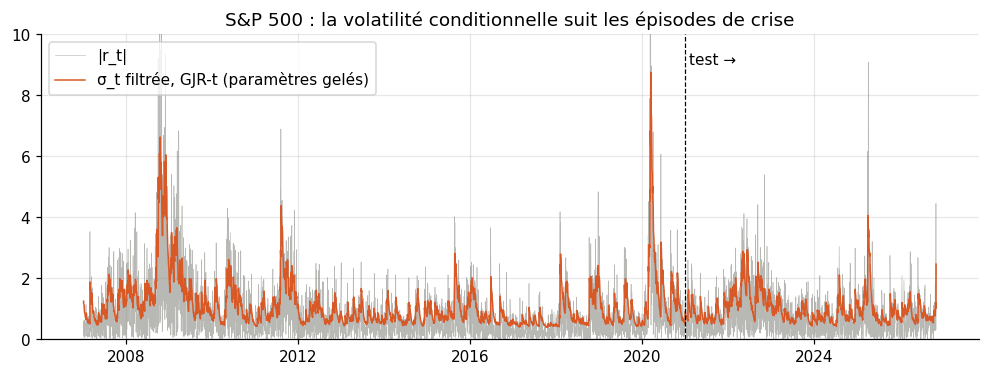

In [9]:
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(np.abs(r_sp), color=GREY, lw=.4, alpha=.6, label="|r_t|")
ax.plot(vol_gjr, color=ORANGE, lw=1, label="σ_t filtrée, GJR-t (paramètres gelés)")
ax.axvline(pd.Timestamp("2021-01-01"), color="k", lw=.8, ls="--"); ax.text(pd.Timestamp("2021-02-01"), 9, "test →")
ax.set_ylim(0, 10); ax.set_title("S&P 500 : la volatilité conditionnelle suit les épisodes de crise"); ax.legend(); plt.show()

Le CRPS recalculé ici est proche de celui du projet. Le petit écart vient de détails d'implémentation (initialisation du
filtre, optimiseur). **GARCH est un concurrent sérieux** : quelques paramètres suffisent à suivre la volatilité.

## 3. L'EDS de bruitage

Un modèle de diffusion **détruit** les données en ajoutant progressivement un bruit gaussien, selon l'EDS à variance
préservée (VP) :

$$
\mathrm d x = -\tfrac12 \beta(t)\, x\,\mathrm dt + \sqrt{\beta(t)}\,\mathrm dW_t
\quad\Longrightarrow\quad
x_k = \sqrt{\bar\alpha_k}\,x_0 + \sqrt{1-\bar\alpha_k}\,\varepsilon,\qquad \varepsilon\sim\mathcal N(0, I).
$$

Le **calendrier** $(\bar\alpha_k)$ fixe la vitesse de destruction. Le projet en utilise deux :

* **quad** ($K = 50$ niveaux, $\sqrt{\beta_k}$ linéaire) pour le modèle B ;
* **cosinus** ($K = 200$ niveaux) pour le modèle A.

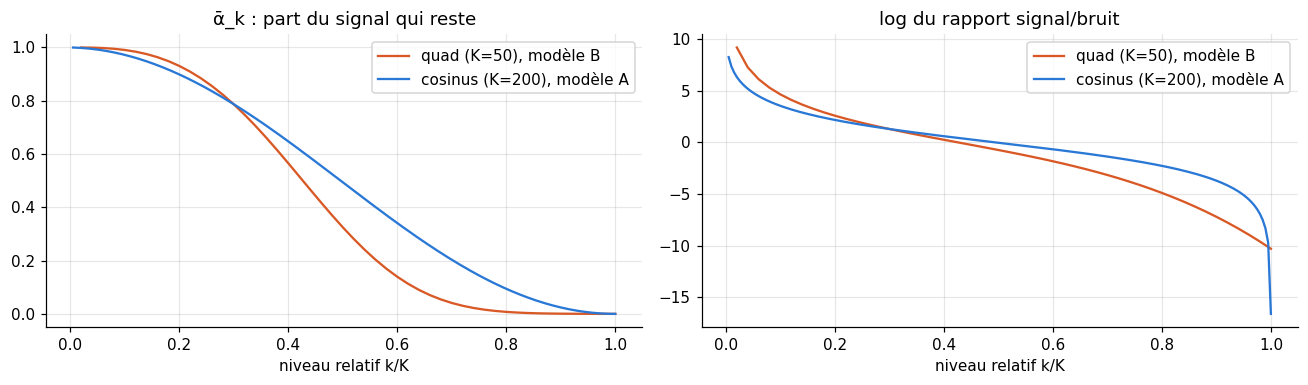

quad : ᾱ_1 = 0.99990, ᾱ_K = 3.35e-05   |   cosinus : ᾱ_1 = 0.99975, ᾱ_K = 6.07e-08


In [10]:
ab_q, ab_c = T.quad_schedule(), T.cosine_schedule()
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for ab, lab, c in [(ab_q, "quad (K=50), modèle B", ORANGE), (ab_c, "cosinus (K=200), modèle A", BLUE)]:
    u = np.arange(1, len(ab) + 1) / len(ab)
    ax[0].plot(u, ab, color=c, label=lab)
    ax[1].plot(u, np.log(ab / (1 - ab)), color=c, label=lab)
ax[0].set_title("ᾱ_k : part du signal qui reste"); ax[1].set_title("log du rapport signal/bruit")
for a in ax: a.set_xlabel("niveau relatif k/K"); a.legend()
plt.tight_layout(); plt.show()
print(f"quad : ᾱ_1 = {ab_q[0]:.5f}, ᾱ_K = {ab_q[-1]:.2e}   |   cosinus : ᾱ_1 = {ab_c[0]:.5f}, ᾱ_K = {ab_c[-1]:.2e}")

On applique le bruitage aux rendements réduits du S&P 500. Au fil des niveaux, les queues épaisses disparaissent et la
loi converge vers $\mathcal N(0,1)$ : c'est le point de départ de la génération.

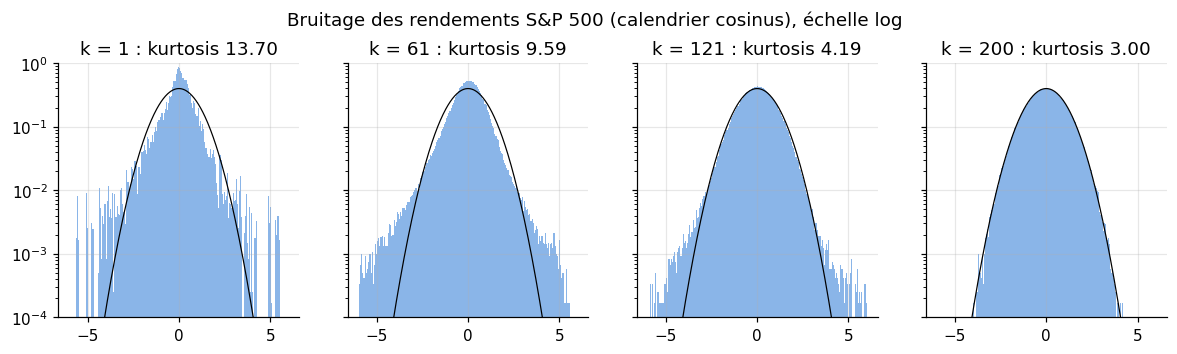

In [11]:
x0 = ((r_train - r_train.mean()) / r_train.std())
x0 = rng.choice(x0, 200_000)
fig, ax = plt.subplots(1, 4, figsize=(13, 3), sharey=True)
grid_ = np.linspace(-6, 6, 400)
for a_, k in zip(ax, [0, 60, 120, 199]):
    a_k = ab_c[k]
    xk = np.sqrt(a_k) * x0 + np.sqrt(1 - a_k) * rng.standard_normal(x0.size)
    a_.hist(xk, bins=200, range=(-6, 6), density=True, color=BLUE, alpha=.55)
    a_.plot(grid_, stats.norm.pdf(grid_), color="k", lw=.8)
    a_.set_title(f"k = {k+1} : kurtosis {stats.kurtosis(xk, fisher=False):.2f}"); a_.set_yscale("log"); a_.set_ylim(1e-4, 1)
fig.suptitle("Bruitage des rendements S&P 500 (calendrier cosinus), échelle log", y=1.04); plt.show()

## 4. Le score et la formule de Tweedie

Pour **remonter** l'EDS, il faut connaître le **score** $\nabla \log p_k(x)$ de la loi bruitée. Il s'apprend par
moindres carrés, grâce à la **formule de Tweedie** :

$$
\mathbb E[x_0 \mid x_k = x] = \frac{x + (1-\bar\alpha_k)\,\nabla\log p_k(x)}{\sqrt{\bar\alpha_k}},
\qquad
\hat\varepsilon(x) = -\sqrt{1-\bar\alpha_k}\;\nabla\log p_k(x).
$$

Le réseau peut prédire $\varepsilon$, $x_0$ ou la « vitesse » $v = \sqrt{\bar\alpha}\,\varepsilon - \sqrt{1-\bar\alpha}\,x_0$ :
ce sont trois rotations du même couple $(x_0, \varepsilon)$. Le modèle A prédit $v$, le modèle B prédit $\varepsilon$.

**Vérification.** Sur une loi jouet à queues épaisses (mélange de deux gaussiennes, kurtosis 5,72), on compare la
moyenne conditionnelle **empirique** (Monte-Carlo, par tranches de $x_k$) à celle que donne Tweedie avec le score exact.

Loi jouet : variance 1.000, kurtosis 5.74 (théorie 5,72)


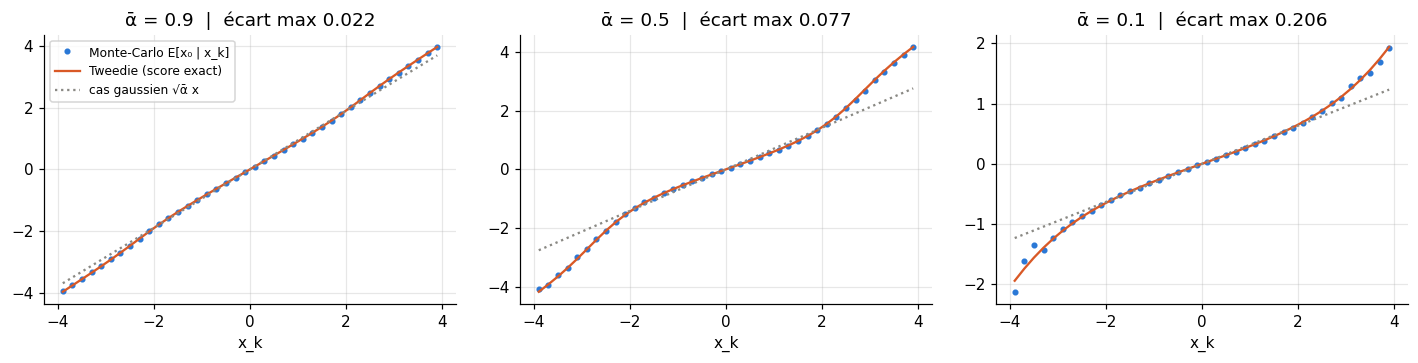

In [12]:
def mix_sample(n):
    comp = rng.random(n) < T.PI_MIX[1]
    return rng.standard_normal(n) * np.sqrt(np.where(comp, T.VAR_MIX[1], T.VAR_MIX[0]))

N = 2_000_000
x0m = mix_sample(N)
print(f"Loi jouet : variance {x0m.var():.3f}, kurtosis {stats.kurtosis(x0m, fisher=False):.2f} (théorie 5,72)")

fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
for a_, a in zip(ax, [0.9, 0.5, 0.1]):
    xk = np.sqrt(a) * x0m + np.sqrt(1 - a) * rng.standard_normal(N)
    bins = np.linspace(-4, 4, 41); idx = np.digitize(xk, bins)
    cen = 0.5 * (bins[1:] + bins[:-1])
    emp = np.array([x0m[idx == i].mean() for i in range(1, len(bins))])
    tw = (cen - np.sqrt(1 - a) * T.mixture_eps(cen, a)) / np.sqrt(a)      # Tweedie avec le bruit optimal exact
    a_.plot(cen, emp, "o", ms=3, color=BLUE, label="Monte-Carlo E[x₀ | x_k]")
    a_.plot(cen, tw, color=ORANGE, label="Tweedie (score exact)")
    a_.plot(cen, np.sqrt(a) * cen, color=GREY, ls=":", label="cas gaussien √ᾱ x")
    a_.set_title(f"ᾱ = {a}  |  écart max {np.nanmax(np.abs(emp - tw)):.3f}"); a_.set_xlabel("x_k")
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()

In [13]:
# Les trois paramétrisations sont des rotations : on retrouve (x0, ε) à partir de v et x_k
a = 0.37; x0_, e_ = rng.standard_normal(5), rng.standard_normal(5)
xk_ = np.sqrt(a) * x0_ + np.sqrt(1 - a) * e_
v_ = np.sqrt(a) * e_ - np.sqrt(1 - a) * x0_
print("x0 retrouvé depuis (x_k, v) :", np.allclose(np.sqrt(a) * xk_ - np.sqrt(1 - a) * v_, x0_))
print("ε  retrouvé depuis (x_k, v) :", np.allclose(np.sqrt(1 - a) * xk_ + np.sqrt(a) * v_, e_))

x0 retrouvé depuis (x_k, v) : True
ε  retrouvé depuis (x_k, v) : True


## 5. Les biais de dispersion : le cœur théorique

Même avec un réseau **parfait**, le schéma numérique qui remonte l'EDS déforme la loi. On le mesure exactement dans le
cas gaussien : données $x_0\sim\mathcal N(0,1)$, débruiteur exact. Chaque pas est affine en l'état, donc la sortie est
$\mathcal N(0, v_0)$ et $v_0$ se calcule par récurrence.

**Théorème (déficit de la règle d'origine).** Le schéma ancestral à variance $\tilde\beta$ sur les $K$ niveaux produit
une loi **trop étroite**, avec

$$
1 - v_0 = \beta_1 + \sum_{k=2}^{K} \frac{(\bar\alpha_{k-1}\beta_k)^2}{1-\bar\alpha_k}.
$$

On vérifie cette forme fermée de trois façons indépendantes : formule, récurrence exacte, simulation.

In [14]:
rows = {}
for name, ab in [("quad (modèle B)", ab_q), ("cosinus (modèle A)", ab_c)]:
    closed = T.deficit_closed_form(ab)
    rec = 1 - T.gaussian_output_std(ab, "ddpm") ** 2
    x, _, _ = T.sample(ab, "ddpm", None, T.gaussian_eps, rng.standard_normal(400_000), rng)
    sd = np.sqrt(1 - closed)
    rows[name] = {"1−v₀ forme fermée": closed, "1−v₀ récurrence": rec, "1−v₀ Monte-Carlo": 1 - x.var(),
                  "écart-type de sortie": sd, "couverture réelle d'un IC 90 %": T.coverage90(sd)}
DEF = pd.DataFrame(rows).T
DEF

,1−v₀ forme fermée,1−v₀ récurrence,1−v₀ Monte-Carlo,écart-type de sortie,couverture réelle d'un IC 90 %
quad (modèle B),0.1131,0.1131,0.1144,0.9418,0.8786
cosinus (modèle A),0.0235,0.0235,0.0196,0.9882,0.8959


**Résultat.** La forme fermée, la récurrence et la simulation coïncident. Le déficit vaut **11,3 %** avec le calendrier
quad du modèle B et **2,4 %** avec le calendrier cosinus du modèle A : un facteur cinq, dû au **seul calendrier**. Un
intervalle « à 90 % » du modèle B ne couvre en réalité que 87,9 % des cas, même avec un réseau parfait.

### DDIM contracte, Euler-Maruyama dilate

* **DDIM** (Euler sur l'EDO de flot) : en notant $\bar\alpha = \cos^2\theta$, chaque pas de $t$ à $s$ multiplie l'état
  par $\cos(\theta_t - \theta_s) < 1$. La loi se **contracte**.
* **Euler-Maruyama** sur l'EDS inverse : $v' - 1 = (1 - B/2)^2 (v - 1) + B^2/4$, donc la loi se **dilate**.

Le nombre de pas devient un **paramètre de calibration**.

In [15]:
# Contrôle de la proposition DDIM : produit des cos(Δθ) sur la grille (le dernier pas va jusqu'à x̂0, θ = 0)
for n in (5, 10, 20, 50):
    g = T.grid(len(ab_c), n)
    th = np.arccos(np.sqrt(ab_c[g]))
    rho = np.prod(np.cos(np.diff(np.r_[th, 0.0])))
    print(f"cosinus, n = {n:3d} : ρ formule = {rho:.5f}   ρ récurrence = {T.gaussian_output_std(ab_c, 'ddim', n):.5f}")

cosinus, n =   5 : ρ formule = 0.73331   ρ récurrence = 0.73331
cosinus, n =  10 : ρ formule = 0.87363   ρ récurrence = 0.87363
cosinus, n =  20 : ρ formule = 0.93806   ρ récurrence = 0.93806
cosinus, n =  50 : ρ formule = 0.97543   ρ récurrence = 0.97543


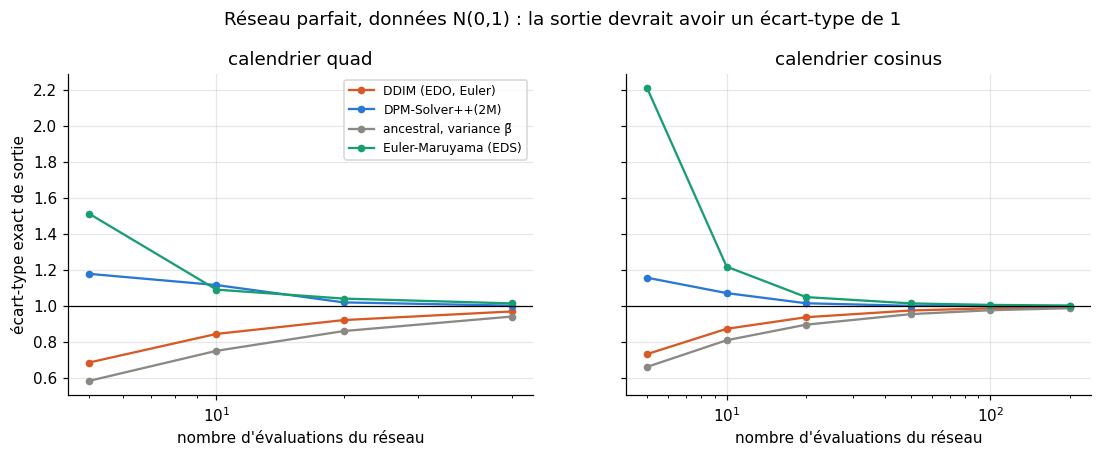

5       10      20      50      100     200
quad    DDIM (EDO, Euler)       0.6865  0.8453  0.9221  0.9702     NaN     NaN
        DPM-Solver++(2M)        1.1790  1.1168  1.0204  1.0023     NaN     NaN
        ancestral, variance β̃  0.5844  0.7513  0.8612  0.9418     NaN     NaN
        Euler-Maruyama (EDS)    1.5128  1.0914  1.0415  1.0147     NaN     NaN
cosinus DDIM (EDO, Euler)       0.7333  0.8736  0.9381  0.9754  0.9877  0.9938
        DPM-Solver++(2M)        1.1575  1.0721  1.0156  1.0015  1.0001  0.9999
        ancestral, variance β̃  0.6623  0.8101  0.8966  0.9554  0.9769  0.9882
        Euler-Maruyama (EDS)    2.2101  1.2191  1.0499  1.0147  1.0065  1.0030

In [16]:
NS = [5, 10, 20, 50, 100, 200]
SAMPLERS = {"ddim": ("DDIM (EDO, Euler)", ORANGE), "dpm2m": ("DPM-Solver++(2M)", BLUE),
            "ancestral": ("ancestral, variance β̃", GREY), "euler_maruyama": ("Euler-Maruyama (EDS)", GREEN)}
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
tab = {}
for a_, (sname, ab) in zip(ax, [("quad", ab_q), ("cosinus", ab_c)]):
    for s, (lab, col) in SAMPLERS.items():
        ns = [n for n in NS if n <= len(ab)]
        sd = [T.gaussian_output_std(ab, s, n) for n in ns]
        a_.plot(ns, sd, "o-", color=col, label=lab, ms=4)
        tab[(sname, lab)] = dict(zip(ns, sd))
    a_.axhline(1, color="k", lw=.8); a_.set_xscale("log"); a_.set_xlabel("nombre d'évaluations du réseau")
    a_.set_title(f"calendrier {sname}")
ax[0].set_ylabel("écart-type exact de sortie"); ax[0].legend(fontsize=8)
fig.suptitle("Réseau parfait, données N(0,1) : la sortie devrait avoir un écart-type de 1", y=1.03); plt.show()
pd.DataFrame(tab).T.round(4)

### Au-delà du cas gaussien : la loi jouet à queues épaisses

Avec le débruiteur exact de la loi jouet (kurtosis 5,72), la contraction touche aussi les **queues** : le quantile à
1 % est encore plus rétréci que l'écart-type.

In [17]:
rows = {}
for s in ["ddim", "ancestral", "euler_maruyama"]:
    for n in (10, 50):
        x, _, _ = T.sample(ab_q, s, n, T.mixture_eps, rng.standard_normal(200_000), rng)
        rows[(SAMPLERS[s][0], n)] = {"écart-type": x.std(), "kurtosis": stats.kurtosis(x, fisher=False),
                                     "q1 % / q1 % vrai": np.quantile(x, .01) / -2.72998,
                                     "écart-type, théorie gaussienne": T.gaussian_output_std(ab_q, s, n)}
print("Calendrier quad, vérité : écart-type 1, kurtosis 5,72, q1 % = −2,730")
pd.DataFrame(rows).T

Calendrier quad, vérité : écart-type 1, kurtosis 5,72, q1 % = −2,730


écart-type  kurtosis  q1 % / q1 % vrai  écart-type, théorie gaussienne
DDIM (EDO, Euler)      10      0.8166    5.1761            0.7730                          0.8453
                       50      0.9593    5.6169            0.9502                          0.9702
ancestral, variance β̃ 10      0.6958    4.7446            0.6338                          0.7513
                       50      0.9267    5.6744            0.9089                          0.9418
Euler-Maruyama (EDS)   10      1.1422    4.8233            1.1186                          1.0914
                       50      1.0235    5.4599            1.0146                          1.0147

### Ce que mesure le vrai modèle A

Sur la validation, l'écart-type relatif des scénarios du modèle A (par rapport à la réalisation) suit exactement le sens
prédit : **DDIM avec peu de pas est beaucoup trop étroit**, DPM-Solver++ est quasi calibré. C'est ce qui a guidé le
choix de l'échantillonneur, **sur la validation**, sans toucher au test.

In [18]:
sv = pd.read_csv(DATA / "panel_I" / "sampler_val.csv")
sv.rename(columns={"nfe": "évaluations", "rel_sd": "écart-type relatif", "crps_fc": "CRPS prévision",
                   "crps_imp": "CRPS imputation", "cov80_fc": "couv. 80 % prév.", "sec_per_1000": "s / 1000 scénarios"})

,sampler,évaluations,CRPS prévision,CRPS imputation,couv. 80 % prév.,cov80_imp,écart-type relatif,s / 1000 scénarios
0,ddim,5,0.6993,0.6478,0.6711,0.6471,0.6283,1.5312
1,ddim,10,0.6890,0.6341,0.7556,0.7422,0.7893,2.5322
2,ddim,20,0.6873,0.6302,0.7924,0.7725,0.8725,4.8037
3,ddim,50,0.6872,0.6285,0.8124,0.7999,0.9230,13.9433
4,dpm2m,5,0.6903,0.6356,0.8413,0.8480,0.9913,1.2874
5,dpm2m,10,0.6916,0.6321,0.8431,0.8372,0.9943,2.7112
6,dpm2m,20,0.6889,0.6292,0.8280,0.8234,0.9642,5.1328
7,ddpm-large,200,0.6860,0.6301,0.8173,0.8145,0.9413,52.6267


## 6. Juger une loi prédictive : les règles de score

Une prévision est une **loi** $F$ ; on la juge face à la réalisation $y$ par le **CRPS** :

$$
\mathrm{CRPS}(F, y) = \mathbb E_F|X - y| - \tfrac12\,\mathbb E_F|X - X'| .
$$

Il est **strictement propre** : son espérance est minimale si et seulement si $F$ est la vraie loi. Mais un modèle de
diffusion ne livre qu'un **ensemble** de $m$ scénarios. L'estimateur naïf remplace $\tfrac12\mathbb E|X-X'|$ par une
moyenne sur $m^2$ couples (diagonale nulle comprise) : il **sous-estime** la dispersion et **favorise les ensembles trop
étroits**. L'estimateur **équitable** divise par $m(m-1)$ et corrige ce biais.

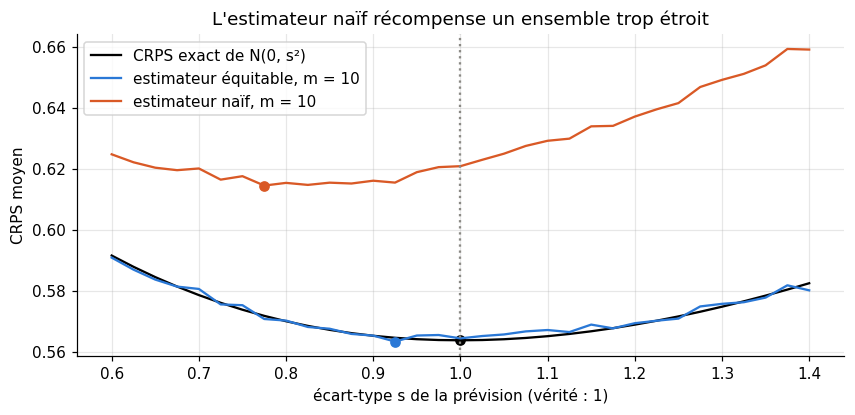

Minimum : exact s = 1.000, équitable s = 0.925, naïf s = 0.775


In [19]:
def crps_ens(ens, y, fair=True):
    # ens : (..., m) ; y : (...)
    m = ens.shape[-1]
    t1 = np.abs(ens - y[..., None]).mean(-1)
    s = np.sort(ens, axis=-1); i = np.arange(1, m + 1)
    pair_sum = 2 * np.sum((2 * i - m - 1) * s, axis=-1)          # Σ_{j,k} |x_j − x_k| en O(m log m)
    return t1 - pair_sum / (2 * (m * (m - 1) if fair else m ** 2))

def crps_gauss(y, sd):
    z = y / sd
    return sd * (z * (2 * stats.norm.cdf(z) - 1) + 2 * stats.norm.pdf(z) - 1 / np.sqrt(np.pi))

m, n_obs = 10, 40_000
y = rng.standard_normal(n_obs)                                   # vérité N(0,1)
sds = np.linspace(.6, 1.4, 33)
exact, naive, fair = [], [], []
for s in sds:
    ens = s * rng.standard_normal((n_obs, m))
    exact.append(crps_gauss(y, s).mean()); naive.append(crps_ens(ens, y, False).mean()); fair.append(crps_ens(ens, y, True).mean())

fig, ax = plt.subplots(figsize=(9, 3.8))
for v, lab, c in [(exact, "CRPS exact de N(0, s²)", "k"), (fair, f"estimateur équitable, m = {m}", BLUE),
                  (naive, f"estimateur naïf, m = {m}", ORANGE)]:
    ax.plot(sds, v, color=c, label=lab); ax.plot(sds[np.argmin(v)], min(v), "o", color=c)
ax.axvline(1, color=GREY, ls=":"); ax.set_xlabel("écart-type s de la prévision (vérité : 1)"); ax.set_ylabel("CRPS moyen")
ax.set_title("L'estimateur naïf récompense un ensemble trop étroit"); ax.legend(); plt.show()
print(f"Minimum : exact s = {sds[np.argmin(exact)]:.3f}, équitable s = {sds[np.argmin(fair)]:.3f}, naïf s = {sds[np.argmin(naive)]:.3f}")

**Platitude en l'échelle.** Près de la vraie loi, le CRPS varie très peu avec l'écart-type (la courbe est plate autour de
1). Un déficit de dispersion de quelques % change donc à peine le CRPS : il faut aussi regarder les **couvertures** et
les **VaR**, ce que fait la suite.

Le projet utilise aussi le score d'énergie (multivarié), le CRPS pondéré dans les queues (twCRPS), le score de
Fissler-Ziegel pour le couple VaR/ES, et les tests de **Diebold-Mariano** pour comparer deux modèles sur les mêmes jours.

## 7. Résultats, panel I : le modèle A face à GARCH

Le modèle A est univarié : il normalise chaque fenêtre par son échelle de volatilité, prédit la vitesse $v$ et échantillonne
avec DPM-Solver++. Il est confronté à la simulation historique (HS), à EWMA, à GARCH-*t*, à GJR-*t* et à la simulation
historique filtrée (FHS), sur **4 392 origines de prévision** (chaque jour du test, horizon 10 jours).

Les chiffres ci-dessous sont **relus** dans les fichiers de résultats ; les modèles de diffusion ne sont pas réentraînés.

In [20]:
ft = pd.read_csv(DATA / "panel_I" / "forecast_table.csv")
cols = ["CRPS_h1", "CRPS_cum10", "twCRPS_h1", "CRPS_RV", "Cov90_h1", "Cov98_h1"]
piv = ft.pivot_table(index="model", columns="index", values=cols).swaplevel(axis=1).sort_index(axis=1)
order = ["HS", "EWMA-N", "GARCH-t", "GJR-t", "FHS", "Diffusion"]
piv.loc[[m for m in order if m in piv.index]].round(4)

index     FTSE100                                                  SP500                                                STOXX50E                              \
          CRPS_RV CRPS_cum10 CRPS_h1 Cov90_h1 Cov98_h1 twCRPS_h1 CRPS_RV CRPS_cum10 CRPS_h1 Cov90_h1 Cov98_h1 twCRPS_h1  CRPS_RV CRPS_cum10 CRPS_h1 Cov90_h1   
model                                                                                                                                                          
HS         0.6287     1.3088  0.4170   0.9203   0.9830    0.0356  0.8831     1.6861  0.5534   0.9062   0.9740    0.0617   0.7976     1.7293  0.5689   0.9139   
EWMA-N     0.6005     1.2768  0.4137   0.8985   0.9659    0.0351  0.6758     1.6327  0.5419   0.8815   0.9719    0.0595   0.7612     1.6821  0.5667   0.8941   
GARCH-t    0.5512     1.2555  0.4104   0.9149   0.9796    0.0345  0.6149     1.5809  0.5368   0.8938   0.9795    0.0596   0.6974     1.6594  0.5606   0.9112   
GJR-t      0.5520     1.2558  0.4119   0.9114   0.9850    0.0348  0.5925     1.5739  0.5340   0.8870   0.9849    0.0590   0.6706     1.6614  0.5583   0.9030   
FHS        0.5349     1.2562  0.4096   0.9019   0.9789    0.0351  0.5977     1.5828  0.5339   0.9041   0.9801    0.0591   0.6662     1.6572  0.5589   0.8982   
Diffusion  0.5181     1.2510  0.4116   0.8903   0.9748    0.0347  0.5685     1.5755  0.5326   0.8993   0.9842    0.0598   0.6132     1.6830  0.5594   0.9064   

index                         
          Cov98_h1 twCRPS_h1  
model                         
HS          0.9836    0.0438  
EWMA-N      0.9645    0.0433  
GARCH-t     0.9788    0.0433  
GJR-t       0.9761    0.0431  
FHS         0.9816    0.0429  
Diffusion   0.9727    0.0429

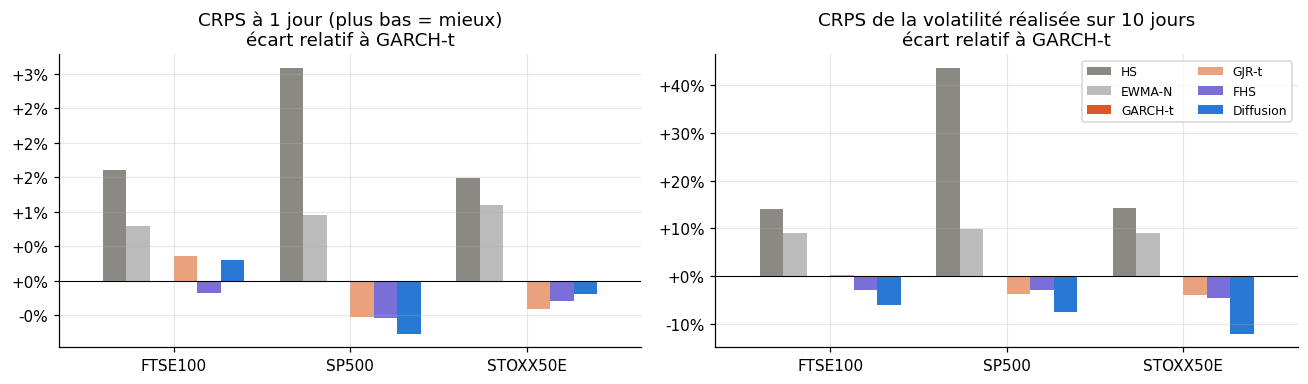

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
sub = ft[ft.model.isin(order)]
for a_, metric, title in [(ax[0], "CRPS_h1", "CRPS à 1 jour (plus bas = mieux)"),
                          (ax[1], "CRPS_RV", "CRPS de la volatilité réalisée sur 10 jours")]:
    p = sub.pivot(index="model", columns="index", values=metric).loc[order]
    rel = p / p.loc["GARCH-t"] - 1
    rel.T.plot.bar(ax=a_, color=[GREY, "#bbb", ORANGE, "#e9a27c", PURPLE, BLUE], width=.8, legend=False)
    a_.axhline(0, color="k", lw=.7); a_.set_title(title + "\nécart relatif à GARCH-t"); a_.set_xlabel("")
    a_.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:+.0%}")); a_.tick_params(axis="x", rotation=0)
ax[1].legend(fontsize=8, ncol=2); plt.tight_layout(); plt.show()

### Tests de Diebold-Mariano : la diffusion contre les meilleurs concurrents

Statistique < 0 : la diffusion a un meilleur score. On compte les tests significatifs à 5 % sur les **scores marginaux**
(CRPS à 1 jour, moyen, cumulé, score d'énergie) contre GARCH-*t*, GJR-*t* et FHS.

In [22]:
dm = pd.read_csv(DATA / "panel_I" / "dm_forecast.csv")
strong = dm[dm.baseline.isin(["GARCH-t", "GJR-t", "FHS"])]
marg = ["crps1", "crps_avg", "crps_cum", "es"]
pv = strong[[f"p_{k}" for k in marg]].values
print(f"Scores marginaux : {pv.size} tests, {np.sum(pv < .05)} significatifs à 5 %.")
print(f"Volatilité réalisée : {np.sum(strong.p_rv < .05)} / {len(strong)} significatifs, "
      f"tous en faveur de la diffusion : {bool((strong.loc[strong.p_rv < .05, 'DM_rv'] < 0).all())}.")
strong.set_index(["index", "baseline"])[[f"DM_{k}" for k in marg] + ["DM_rv", "p_rv"]].round(3)

Scores marginaux : 36 tests, 0 significatifs à 5 %.
Volatilité réalisée : 4 / 9 significatifs, tous en faveur de la diffusion : True.


DM_crps1  DM_crps_avg  DM_crps_cum  DM_es  DM_rv   p_rv
index    baseline                                                         
SP500    GARCH-t     -1.315       -0.058       -0.339 -0.177 -2.123  0.034
         GJR-t       -0.409        0.374        0.110  0.418 -1.144  0.253
         FHS         -0.356       -0.015       -0.488  0.107 -1.370  0.171
STOXX50E GARCH-t     -0.358       -0.537        1.256 -0.992 -4.480  0.000
         GJR-t        0.411        0.127        1.438  0.075 -3.029  0.002
         FHS          0.200        0.430        1.332  0.116 -3.020  0.003
FTSE100  GARCH-t      0.493       -0.135       -0.268 -0.434 -1.799  0.072
         GJR-t       -0.091       -0.875       -0.351 -0.958 -1.719  0.086
         FHS          0.816        0.881       -0.394 -0.414 -0.914  0.361

**Parité.** Sur les scores marginaux, aucun test n'est significatif : le modèle A **égale** GARCH-*t*, GJR-*t* et FHS. Il
fait mieux sur la **volatilité réalisée** de la trajectoire, ce qui mesure la qualité de la dynamique sur 10 jours.

### Par régime de marché, et fidélité des faits stylisés

In [23]:
reg = pd.read_csv(DATA / "panel_I" / "forecast_by_regime.csv")
display(reg.set_index(["index", "regime"]).round(4))
fid = pd.read_csv(DATA / "panel_I" / "fidelity_table.csv")
fid.columns = [c.replace("$", "").replace("\\", "") for c in fid.columns]
fid["Index"] = fid["Index"].str.replace("\\", "", regex=False); fid["Source"] = fid["Source"].str.replace("$", "", regex=False)
fid

HS  EWMA-N  GARCH-t   GJR-t     FHS  Diffusion
index    regime                                                       
SP500    calm       0.3932  0.3723   0.3700  0.3685  0.3682     0.3643
         medium     0.4777  0.4787   0.4722  0.4715  0.4698     0.4664
         turbulent  0.7891  0.7746   0.7681  0.7617  0.7634     0.7671
STOXX50E calm       0.4600  0.4528   0.4479  0.4466  0.4478     0.4465
         medium     0.4904  0.4912   0.4822  0.4861  0.4836     0.4874
         turbulent  0.7563  0.7563   0.7516  0.7421  0.7453     0.7444
FTSE100  calm       0.3503  0.3424   0.3453  0.3430  0.3442     0.3479
         medium     0.3678  0.3624   0.3623  0.3607  0.3584     0.3598
         turbulent  0.5330  0.5363   0.5238  0.5321  0.5264     0.5274

,Index,Source,Kurt.,Kurt. (std.),Skew. (std.),"ACF |r|, lag 1","ACF |r|, lags 1--5","ACF r, lag 1",Leverage
0,S&P 500,Real (test),9.2,3.99,-0.16,0.016,0.041,-0.020,-0.107
1,S&P 500,Diffusion,11.5,4.16,-0.21,0.047,0.050,-0.063,-0.095
2,S&P 500,GARCH-t,27.1,4.30,-0.01,0.070,0.052,-0.021,-0.006
3,S&P 500,GJR-t,19.5,4.85,0.30,0.093,0.067,-0.018,-0.054
4,Euro Stoxx 50,Real (test),6.8,4.09,-0.19,0.087,0.041,-0.081,-0.120
5,Euro Stoxx 50,Diffusion,9.1,3.87,-0.06,0.033,0.037,-0.033,-0.108
6,Euro Stoxx 50,GARCH-t,12.1,3.75,-0.00,0.047,0.034,-0.020,0.000
7,Euro Stoxx 50,GJR-t,13.0,4.02,0.19,0.055,0.042,-0.032,-0.053
8,FTSE 100,Real (test),7.7,4.43,-0.27,0.101,0.034,-0.037,-0.090
9,FTSE 100,Diffusion,8.6,3.77,-0.11,0.036,0.038,-0.018,-0.106


Sur la fidélité, l'effet de levier des scénarios de diffusion (−0,095 sur le S&P 500) est proche du réel (−0,107), alors
que GARCH-*t* n'en a presque pas (−0,006) : sa structure symétrique ne peut pas le produire.

### VaR à 1 % et 5 % : tests de Kupiec et de Christoffersen

In [24]:
var = pd.read_csv(DATA / "panel_I" / "var_table.csv")
v = var[var.model.isin(order)].copy()
v["attendus"] = (v.n * v.alpha).round(1)
v.pivot_table(index=["index", "model"], columns="alpha", values=["hits", "attendus", "p_cc"]).round(3).loc[
    [(i, m) for i in INDICES for m in order]]

attendus        hits          p_cc       
alpha                  0.01  0.05  0.01   0.05   0.01   0.05
index    model                                              
SP500    HS            14.6  73.0  18.0   68.0  0.322  0.269
         EWMA-N        14.6  73.0  28.0   93.0  0.006  0.065
         GARCH-t       14.6  73.0  25.0   98.0  0.034  0.009
         GJR-t         14.6  73.0  17.0  101.0  0.677  0.004
         FHS           14.6  73.0  14.0   67.0  0.862  0.655
         Diffusion     14.6  73.0  11.0   74.0  0.117  0.789
STOXX50E HS            14.6  73.2   8.0   65.0  0.000  0.005
         EWMA-N        14.6  73.2  31.0   82.0  0.000  0.468
         GARCH-t       14.6  73.2  19.0   72.0  0.279  0.959
         GJR-t         14.6  73.2  21.0   83.0  0.173  0.296
         FHS           14.6  73.2  13.0   71.0  0.239  0.079
         Diffusion     14.6  73.2  22.0   63.0  0.003  0.450
FTSE100  HS            14.7  73.4  13.0   59.0  0.237  0.000
         EWMA-N        14.7  73.4  29.0   78.0  0.000  0.028
         GARCH-t       14.7  73.4  18.0   69.0  0.561  0.001
         GJR-t         14.7  73.4  14.0   78.0  0.860  0.003
         FHS           14.7  73.4  14.0   67.0  0.296  0.002
         Diffusion     14.7  73.4  17.0   69.0  0.000  0.005

### Imputation de rendements manquants

On cache des rendements (au hasard : 10 % ou 30 % ; par blocs : 5 ou 20 jours) et on demande une loi pour les valeurs
manquantes. Concurrents : interpolation linéaire, ponts browniens (EWMA ou échelle locale), lisseur GJR-*t*.

In [25]:
imp = pd.read_csv(DATA / "panel_I" / "imputation_pooled.csv")
p = imp.pivot(index="model", columns="scenario", values="CRPS").loc[["Linear", "BB-EWMA", "BB-local", "GJR-t", "Diffusion"]]
display(p.round(4))
dmi = pd.read_csv(DATA / "panel_I" / "dm_imputation.csv")
w = dmi[dmi.baseline == "GJR-t"] if "GJR-t" in set(dmi.baseline) else dmi
print("Diffusion contre", w.baseline.unique(), ":", (w.p < .05).sum(), "tests significatifs sur", len(w))

scenario,block-20,block-5,random-10%,random-30%
model,,,,
Linear,0.6964,0.6440,0.5100,0.5327
BB-EWMA,0.5194,0.4834,0.3795,0.3965
BB-local,0.5140,0.4781,0.3740,0.3896
GJR-t,0.5104,0.4661,0.3669,0.3840
Diffusion,0.5111,0.4726,0.3661,0.3858


Diffusion contre ['GJR-t'] : 1 tests significatifs sur 12


### Ablations et données synthétiques

Chaque choix du modèle A est retiré à tour de rôle (sur la validation). Prédire $\varepsilon$ au lieu de $v$ **double** le
CRPS : c'est le choix le plus décisif.

In [26]:
abl = pd.read_csv(DATA / "panel_I" / "ablation.csv")
display(abl.round(4))
display(pd.read_csv(DATA / "panel_I" / "synthetic_forecast.csv").round(4))

,variant,crps_fc,crps_imp,cov80_fc,cov80_imp,t_fc,t_imp,best_it
0,main,0.6911,0.6180,0.8237,0.7990,NaN,NaN,1750.0
1,global-norm,0.6943,0.6210,0.8330,0.8106,0.9642,1.0796,1250.0
2,eps-param,1.3214,1.0575,0.9287,0.9202,9.9236,6.5057,4000.0
3,no-covariates,0.6996,0.6240,0.8173,0.8022,4.1109,1.9914,2750.0
4,no-attention,0.6964,0.6239,0.8190,0.7889,1.6208,1.6407,2000.0
5,no-regularisation,0.6996,0.6222,0.8117,0.7939,2.3164,1.1604,2000.0
6,ensemble,0.6925,0.6249,0.8227,0.7947,0.4010,1.1961,NaN
7,seed-1,0.6935,0.6212,0.8200,0.7934,1.3167,1.4264,NaN
8,seed-2,0.6942,0.6224,0.8177,0.7961,1.4012,1.7511,NaN


,model,CRPS_h1,CRPS_avg,CRPS_cum10,Energy,twCRPS_h1,CRPS_RV,Cov90_h1,gap
0,HS,0.5175,0.5202,1.6986,2.0639,0.0862,0.9106,0.8927,3.4339
1,EWMA-N,0.5013,0.5063,1.6426,2.0004,0.0812,0.6458,0.8914,0.6608
2,GARCH-t,0.5008,0.5029,1.6270,1.9879,0.0805,0.5792,0.8975,-0.0102
3,GJR-t,0.4965,0.5031,1.6284,1.9882,0.0804,0.5742,0.9070,0.0311
4,FHS,0.5001,0.5037,1.6395,1.9912,0.0808,0.5820,0.9016,0.1498
5,Diffusion,0.5028,0.5076,1.6313,2.0057,0.0815,0.6551,0.9117,0.9267
6,Oracle,0.5006,0.5030,1.6327,1.9887,0.0810,0.5744,0.9043,0.0000


Sur données **synthétiques** tirées d'un GARCH connu, aucun modèle ne peut battre le vrai processus. La colonne `gap`
mesure l'écart à cet optimum : c'est un contrôle que la méthode d'évaluation détecte bien les bons modèles.

## 8. Résultats, panel II : le modèle B et la loi jointe

Le modèle B (type CSDI) génère **conjointement** les huit actifs. Évaluation : 135 fenêtres hebdomadaires, horizon
5 jours, 100 scénarios par fenêtre, 3 graines.

### Prévision

In [27]:
fc = js("panel_II/forecast_test")
LAB = {"naive": "Naïve", "garch": "GARCH", "deepar": "DeepAR", "csdi": "Modèle B (CSDI)"}
summ = pd.DataFrame({LAB[k]: {m: fc["summary"][k][m][0] for m in ["crps", "crps_sum", "mae", "coverage_90", "width_90"]}
                     for k in LAB}).T
display(summ.round(4))
stt = js("panel_II/statistics_test")["tasks"]["prévision"]["comparisons"]
print("Écart de CRPS modèle B − concurrent (bootstrap hiérarchique : blocs de 4 semaines et entraînements) :")
for k in ("naive", "garch", "deepar"):
    d = stt[k]["hierarchical"]
    print(f"  B − {LAB[k]:7s} = {d['mean']:+.4f}   IC 95 % [{d['low']:+.4f} ; {d['high']:+.4f}]   établi : {d['significant']}")
print(f"Couverture 90 % du modèle B : {summ.loc['Modèle B (CSDI)', 'coverage_90']:.3f} "
      f"(prédiction de la théorie, calendrier quad : {DEF.iloc[0, -1]:.3f})")

,crps,crps_sum,mae,coverage_90,width_90
Naïve,0.5278,1.8080,0.7153,0.8754,2.9506
GARCH,0.5158,1.7528,0.7049,0.8846,2.8759
DeepAR,0.5145,1.7468,0.7057,0.8778,2.8152
Modèle B (CSDI),0.5206,1.7737,0.7065,0.8649,2.7710


Écart de CRPS modèle B − concurrent (bootstrap hiérarchique : blocs de 4 semaines et entraînements) :
  B − Naïve   = -0.0072   IC 95 % [-0.0132 ; -0.0022]   établi : True
  B − GARCH   = +0.0048   IC 95 % [+0.0015 ; +0.0083]   établi : True
  B − DeepAR  = +0.0061   IC 95 % [+0.0025 ; +0.0103]   établi : True
Couverture 90 % du modèle B : 0.865 (prédiction de la théorie, calendrier quad : 0.879)


**Le modèle B fait moins bien que GARCH** et sous-couvre, dans le sens et l'ordre de grandeur que prédit le
théorème de l'étape 5 pour son calendrier quad. La théorie numérique **explique** le résultat empirique.

### Imputation et prix manquants

Un prix manquant n'efface pas l'information : la **somme** des rendements sur le trou est connue (elle vaut l'écart des
log-prix aux deux bords). Un estimateur gaussien multivarié (krigeage) qui exploite cette contrainte et les autres
marchés du même jour est un concurrent redoutable.

In [28]:
ip = js("panel_II/imputation_probabiliste_test")["results"]
print("Rendements manquants : écart de CRPS modèle B − méthode (négatif : B meilleur), IC 95 %")
rows = {}
for task, lab in (("points", "points isolés"), ("blocks", "blocs de 5 jours")):
    for meth, v in ip[task].items():
        d = v["csdi_minus_method"]["crps"]
        rows[(lab, meth)] = {"CRPS méthode": v["crps"], "B − méthode": d["mean"], "bas": d["low"], "haut": d["high"],
                             "établi": d["low"] > 0 or d["high"] < 0}
display(pd.DataFrame(rows).T)

Rendements manquants : écart de CRPS modèle B − méthode (négatif : B meilleur), IC 95 %


CRPS méthode B − méthode     bas    haut établi
points isolés    pont_brownien              0.5122     -0.0313 -0.0426 -0.0222   True
                 ewma_univarie              0.5161     -0.0353 -0.0439 -0.0282   True
                 ewma_multivarie            0.4727      0.0081 -0.0004  0.0184  False
                 lisseur_particulaire        0.506     -0.0252 -0.0343 -0.0179   True
blocs de 5 jours pont_brownien              0.5162      -0.026 -0.0371 -0.0172   True
                 ewma_univarie              0.5193     -0.0291  -0.037 -0.0231   True
                 ewma_multivarie            0.4854      0.0048  -0.005  0.0152  False
                 lisseur_particulaire       0.5104     -0.0202 -0.0282  -0.014   True

In [29]:
# Prix manquants : une échelle d'information. Plus une méthode exploite d'information, plus son CRPS baisse.
INFO = {"knn": "passé", "interpolation_log_prix": "somme", "knn_krigeage": "passé + somme",
        "ewma_multivarie": "même jour", "pont_ewma": "passé + somme", "pont_local": "après + somme",
        "lisseur_gjr": "passé + après + somme", "ewma_contrainte": "même jour + somme"}
res = js("panel_II/imputation_prix_test")["results"]
cmp_ = js("panel_II/imputation_prix_test_comparaisons")
pd.DataFrame({k: {"information utilisée": INFO[k], "CRPS": res[k]["crps"], "couverture 90 %": res[k].get("coverage_90"),
                  "écart à la meilleure [IC 95 %]": (f"+{cmp_[k]['crps']['mean']:.4f} [{cmp_[k]['crps']['low']:.4f} ; "
                                                     f"{cmp_[k]['crps']['high']:.4f}]" if k in cmp_ else "référence")}
              for k in INFO}).T.sort_values("CRPS", ascending=False)

,information utilisée,CRPS,couverture 90 %,écart à la meilleure [IC 95 %]
knn,passé,0.6828,0.0,+0.2800 [0.2577 ; 0.3064]
interpolation_log_prix,somme,0.5876,0.0,+0.1848 [0.1651 ; 0.2085]
knn_krigeage,passé + somme,0.5863,0.0,+0.1835 [0.1656 ; 0.2047]
ewma_multivarie,même jour,0.4722,0.8743,+0.0694 [0.0645 ; 0.0751]
pont_local,après + somme,0.4338,0.8829,+0.0310 [0.0194 ; 0.0445]
pont_ewma,passé + somme,0.4321,0.9003,+0.0293 [0.0184 ; 0.0422]
lisseur_gjr,passé + après + somme,0.4268,0.8863,+0.0240 [0.0133 ; 0.0370]
ewma_contrainte,même jour + somme,0.4028,0.8653,référence


### Loi jointe : mêmes marges, VaR opposées

GJR (marchés indépendants) et GJR-CCC (copule gaussienne de corrélation $R$) ont **exactement les mêmes lois
marginales** ; seule change la dépendance du jour même. Aucun score marginal ne peut les distinguer, mais la VaR d'un
portefeuille équipondéré, si :

$$
\operatorname{Var}\Big(\tfrac1D\sum_d z_d\Big) = \frac{1}{D^2}\sum_{d,e} R_{de}.
$$

In [30]:
lj = js("panel_II/loi_jointe_test")["methods"]
rows = {}
for k, mth in lj.items():
    for a in ("0.01", "0.05"):
        od = mth["var"][a]["one_day"]
        rows[(mth["label"], a)] = {"dépassements": od["kupiec"]["hits"], "attendus": od["kupiec"]["expected"],
                                   "p Kupiec": od["kupiec"]["p_value"], "p Christoffersen": od["christoffersen"]["p_value"]}
pd.DataFrame(rows).T.round(4)

dépassements  attendus  p Kupiec  p Christoffersen
Naïve                       0.01          24.0      6.75    0.0000            0.0001
                            0.05          53.0     33.75    0.0016            0.0018
GARCH(1,1) Student          0.01          17.0      6.75    0.0009            0.0004
                            0.05          53.0     33.75    0.0016            0.0223
GJR-GARCH(1,1) Student      0.01          19.0      6.75    0.0001            0.0012
                            0.05          48.0     33.75    0.0176            0.0053
GJR-CCC (copule gaussienne) 0.01           6.0      6.75    0.7675            0.0000
                            0.05          25.0     33.75    0.1059            0.0001

**Contrôle sur les scénarios bruts.** On recharge les 300 scénarios × 135 fenêtres × 8 actifs × 5 jours des deux
modèles. Les écarts-types **par actif** doivent être identiques, et ceux du **portefeuille** différents.

In [31]:
load = lambda m: np.concatenate([np.load(DATA / "panel_II" / f"prevision_test_{m}_seed{s}.npz")["samples"].astype(float)
                                 for s in range(3)])
S_gjr, S_ccc = load("gjr"), load("ccc")
print("forme des scénarios (scénario, fenêtre, actif, jour) :", S_gjr.shape)
marg = pd.DataFrame({"GJR indépendants": S_gjr.std(axis=(0, 1, 3)), "GJR-CCC": S_ccc.std(axis=(0, 1, 3))}, index=ASSETS_II)
display(marg.T.round(3))
port = lambda S: S.mean(axis=2)
print(f"Écart-type du portefeuille : indépendants {port(S_gjr).std():.3f}  |  CCC {port(S_ccc).std():.3f}  "
      f"→ rapport {port(S_ccc).std() / port(S_gjr).std():.2f}")

Rm = np.array(js("panel_II/forecast_ccc_test")["correlation"]); one = np.ones(8)
print(f"Théorie : √(1ᵀR1)/√8 = {np.sqrt(one @ Rm @ one) / np.sqrt(8):.2f}")

forme des scénarios (scénario, fenêtre, actif, jour) : (300, 135, 8, 5)


,S&P 500,Euro Stoxx 50,FTSE 100,Nikkei 225,Or,Brent,EUR/USD,Oblig. US
GJR indépendants,0.921,0.823,0.796,1.233,1.315,1.167,0.817,0.970
GJR-CCC,0.918,0.826,0.791,1.224,1.354,1.161,0.819,0.974


Écart-type du portefeuille : indépendants 0.362  |  CCC 0.451  → rapport 1.25
Théorie : √(1ᵀR1)/√8 = 1.31


Si l'on calcule la VaR 1 % en supposant les marchés indépendants, le vrai portefeuille la dépasse 3.2% du temps au lieu de 1 %.


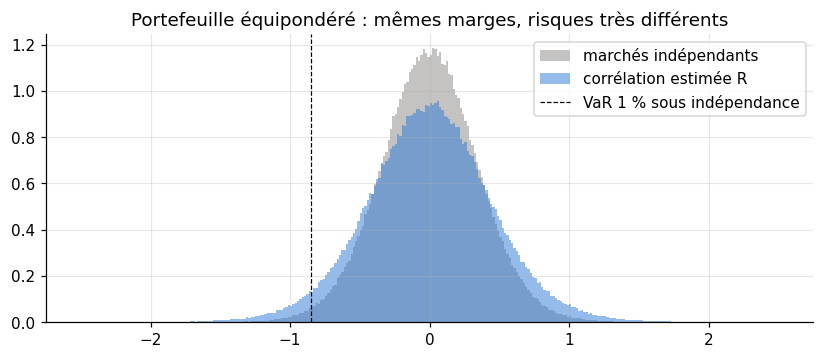

In [32]:
# Simulation : marges de Student identiques, seule la corrélation change
nu, n = 5.0, 400_000
to_t = lambda u: np.sqrt((nu - 2) / nu) * stats.t.ppf(stats.norm.cdf(u), nu)
g_c = rng.standard_normal((n, 8)) @ np.linalg.cholesky(Rm).T
p_c, p_i = to_t(g_c).mean(1), to_t(rng.standard_normal((n, 8))).mean(1)
v_i = np.quantile(p_i, .01)
print(f"Si l'on calcule la VaR 1 % en supposant les marchés indépendants, le vrai portefeuille la dépasse "
      f"{np.mean(p_c < v_i):.1%} du temps au lieu de 1 %.")
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.hist(p_i, bins=300, range=(-2.5, 2.5), density=True, alpha=.5, color=GREY, label="marchés indépendants")
ax.hist(p_c, bins=300, range=(-2.5, 2.5), density=True, alpha=.5, color=BLUE, label="corrélation estimée R")
ax.axvline(v_i, color="k", ls="--", lw=.8, label="VaR 1 % sous indépendance")
ax.set_title("Portefeuille équipondéré : mêmes marges, risques très différents"); ax.legend(); plt.show()

Sur le test, le modèle indépendant subit **19 dépassements** de sa VaR 1 % contre **6** pour GJR-CCC, pour 6,75
attendus : un facteur trois, à marges identiques. **Les scores marginaux ne disent rien de la loi jointe.**

## 9. Synthèse

| Maillon | Résultat | Où dans ce notebook |
|---|---|---|
| Données | queues épaisses, regroupement de volatilité, effet de levier, dépendance entre marchés | § 1 |
| Référence | GARCH-*t* / GJR-*t* réestimés, paramètres et CRPS retrouvés | § 2 |
| Théorie | déficit de la règle d'origine en forme fermée (11,3 % quad, 2,4 % cosinus), DDIM contracte, Euler-Maruyama dilate | § 5 |
| Évaluation | l'estimateur naïf du CRPS favorise les ensembles trop étroits ; le CRPS est plat en l'échelle | § 6 |
| Modèle A | parité avec GARCH-*t*, GJR-*t* et FHS sur les scores marginaux (0 test DM significatif) ; meilleur sur la volatilité réalisée et l'effet de levier | § 7 |
| Modèle B | moins bon que GARCH ; sous-couverture dans le sens prédit par la théorie | § 8 |
| Imputation | les diffusions battent les méthodes univariées, mais le krigeage gaussien qui exploite les mêmes informations fait au moins aussi bien | § 7, § 8 |
| Loi jointe | mêmes marges, VaR de portefeuille qui diffèrent d'un facteur trois | § 8 |

### Pourquoi le modèle A et pas le modèle B ?

Ils partagent le même cadre et diffèrent par trois choix, que la théorie permet de départager :

1. **La normalisation de l'échelle.** A divise chaque fenêtre par son échelle de volatilité ; le réseau n'a plus qu'à
   apprendre la **forme** de la loi, ce qui est à sa portée avec 5 000 observations.
2. **La quantité prédite.** A prédit $v$ ; prédire $\varepsilon$ double le CRPS (ablation, § 7).
3. **Le schéma d'échantillonnage.** B échantillonne avec la règle d'origine sur un calendrier quad, dont le déficit de
   variance est de 11,3 % même avec un réseau parfait. A utilise un calendrier cosinus et DPM-Solver++, quasi calibrés.

**Verdict.** Un modèle de diffusion bien construit égale les meilleurs GARCH sur des rendements quotidiens et reproduit
mieux la dynamique des trajectoires. Mais il ne les bat pas nettement sur les scores marginaux, et ses choix numériques
(calendrier, schéma, nombre de pas) décident autant du résultat que le réseau lui-même.